In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, EngFormatter
from scipy.signal import welch

# Load either the older Fluke CSV columns or the newer timestamp,voltage CSVs.
def load(filename):
    df = pd.read_csv(filename)
    if 'elapsed_s' in df.columns:
        seconds = df['elapsed_s'].to_numpy()
        voltage = df['voltage_V'].to_numpy()
        start = None
    else:
        df = pd.read_csv(filename, header=None, names=['time', 'voltage'])
        time = pd.to_datetime(df['time'], utc=True, format='ISO8601')
        start = time.iloc[0]
        seconds = (time-start).dt.total_seconds().to_numpy()
        voltage = df['voltage'].to_numpy()
    v = pd.Series(voltage, index=seconds)
    v.attrs['start'] = start
    duration = seconds[-1]-seconds[0]
    sps = (len(v)-1)/duration
    print(f'{filename}: {len(v)} readings, {duration/3600:.3f} h, {sps:.6f} SPS')
    return v, sps

f_night, mf_night = load('fullscale/8588A_fullscale_10V_20261126-232806.csv')
k_night, mk_night = load('fullscale/3458B_fullscale_10V_20261126-232800.csv')

# Align captures into 5s intervals, using their timestamps
start_gap = (k_night.attrs['start']-f_night.attrs['start']).total_seconds()
block = np.floor((k_night.index.to_numpy()+start_gap)/5).astype(int)
keysight = pd.Series(k_night.to_numpy(), index=block).groupby(level=0).agg(['mean','count'])
keysight = keysight.loc[(keysight.index >= 0) & (keysight.index < len(f_night))
                        & keysight['count'].between(99,101)]
paired = pd.DataFrame({'8588A_V': f_night.to_numpy()[keysight.index],
                       '3458B_avg100_V': keysight['mean'].to_numpy()}, index=keysight.index)
print(f'3458B readings per aligned interval: {keysight["count"].min()}–{keysight["count"].max()}')

# Exclude the first hour (temperature disturbance)
warmup_s = 3600
f_night = f_night.loc[f_night.index >= warmup_s].copy()
f_night.index = f_night.index - warmup_s
paired = paired.loc[paired.index >= warmup_s/5].copy()
paired.index = paired.index - warmup_s/5

f100 = paired['8588A_V']
k100 = paired['3458B_avg100_V']
print(f'Simultaneous results: {len(paired)} pairs, 0.2 SPS')

fullscale/8588A_fullscale_10V_20261126-232806.csv: 6480 readings, 8.999 h, 0.200000 SPS
fullscale/3458B_fullscale_10V_20261126-232800.csv: 648000 readings, 9.000 h, 19.999699 SPS
3458B readings per aligned interval: 99–101
Simultaneous results: 5756 pairs, 0.2 SPS


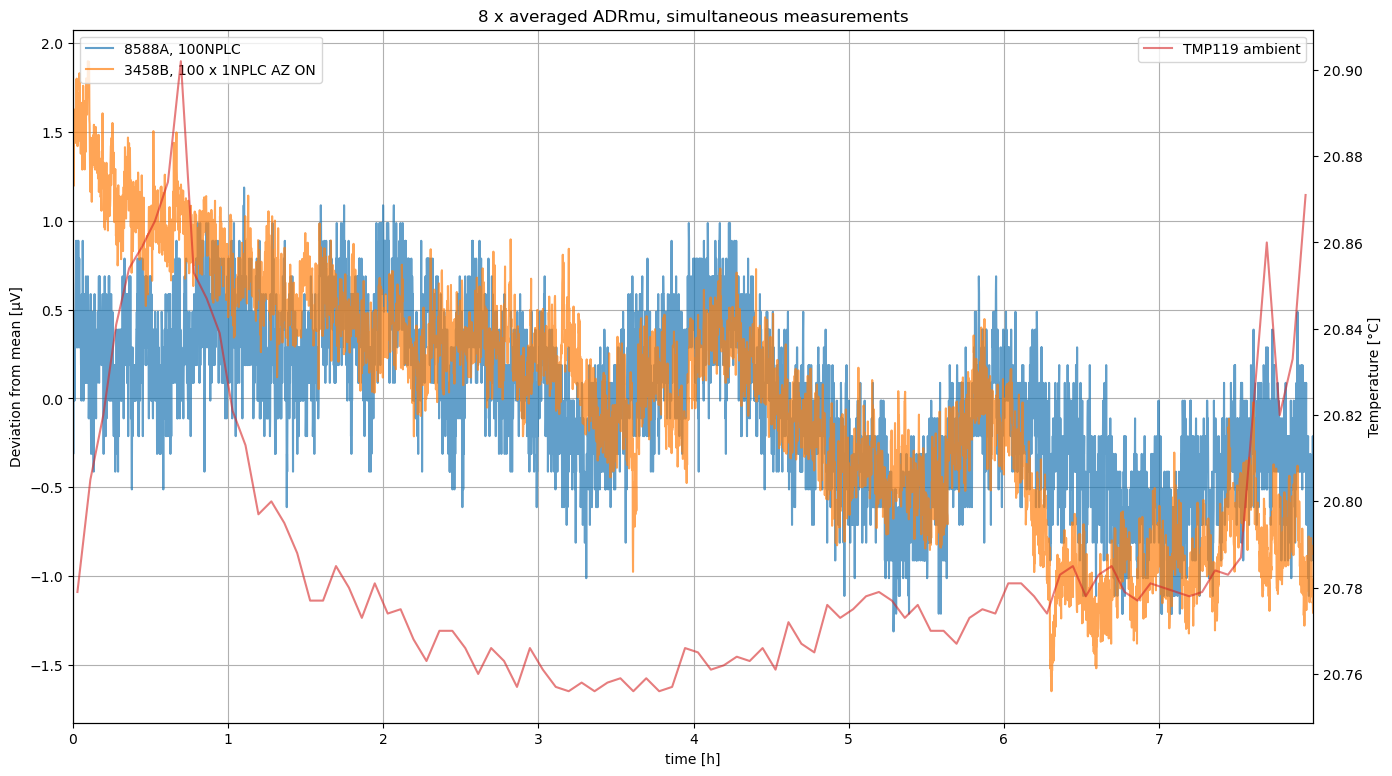

In [59]:
# Room temp overlay
temp = pd.read_csv('fullscale/Temperature-data-2026-11-27 12_15_10.csv')
temp_time = pd.to_datetime(temp['Time']).dt.tz_localize('Europe/Berlin').dt.tz_convert('UTC')
temp_C = temp.iloc[:, 1].str.replace('°C', '', regex=False).str.strip().astype(float)
temp_h = (temp_time - f_night.attrs['start']).dt.total_seconds()/3600

def overlay_temperature(ax, hours):
    m = temp_h.between(0, hours)
    ax2 = ax.twinx()
    ax2.plot(temp_h[m], temp_C[m], color='tab:red', alpha=0.6, label='TMP119 ambient')
    ax2.set_ylabel('Temperature [°C]')
    ax2.legend(loc='upper right')
    ax.set_xlim(0, hours)


fig, ax = plt.subplots(figsize=(16,9))
t = paired.index.to_numpy()*5/3600
ax.plot(t, (f100-f100.mean())*1e6, label='8588A, 100NPLC', alpha=0.7)
ax.plot(t, (k100-k100.mean())*1e6, label='3458B, 100 x 1NPLC AZ ON', alpha=0.7)
ax.set_xlabel('time [h]')
ax.set_ylabel('Deviation from mean [µV]')
ax.set_title('8 x averaged ADRmu, simultaneous measurements')
ax.grid(True)
ax.legend(loc='upper left')
overlay_temperature(ax, t[-1])
plt.show()

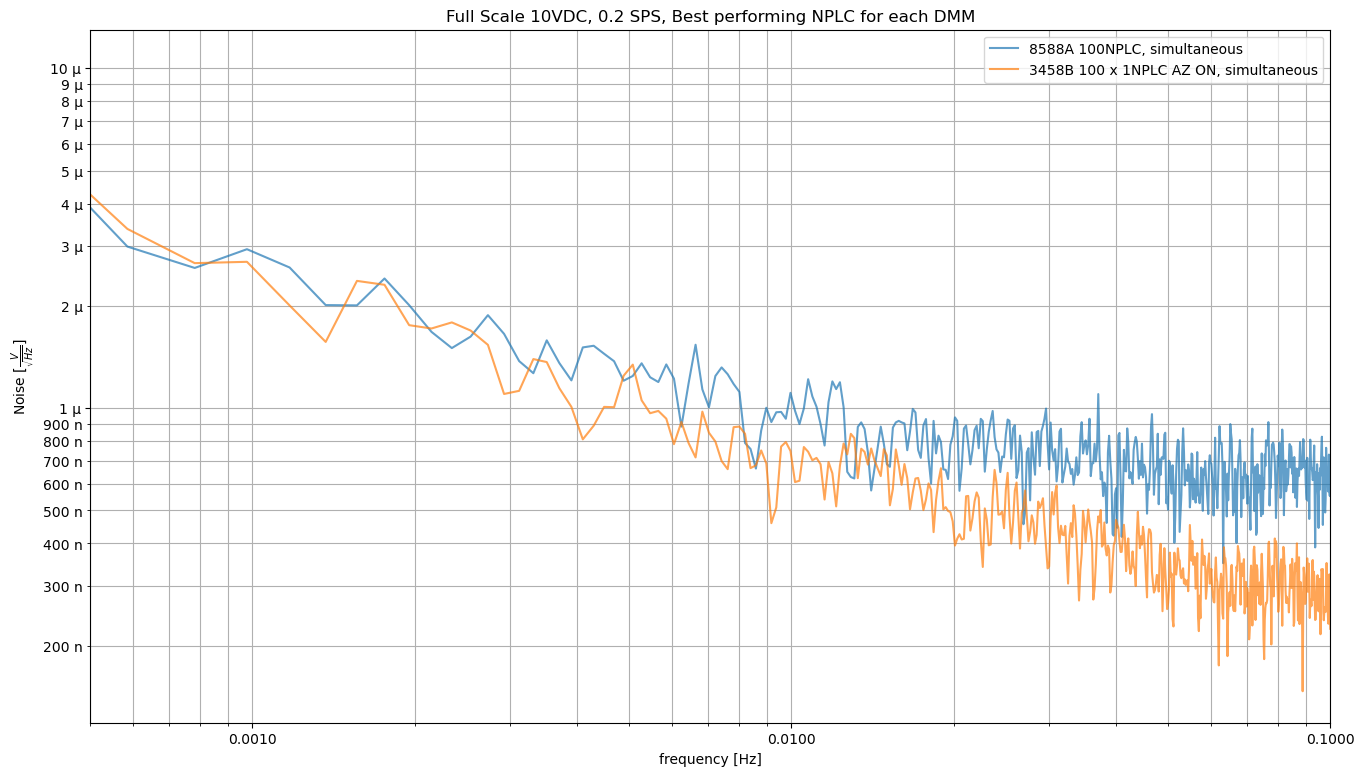

In [60]:
def process(v, sps, nfft, meter_name):
    f, psd = welch(np.asarray(v), fs=sps, window='hann', nperseg=nfft, noverlap=nfft//2)
    plt.plot(f[1:], np.sqrt(psd[1:]), label=meter_name, alpha=0.7)

fig, ax = plt.subplots(figsize=(16,9))
plt.loglog()
plt.xlim([0.0005,0.1])
plt.xlabel('frequency [Hz]')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4f'))
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
plt.ylabel(r'Noise [$\frac{V}{\sqrt{Hz}}$]')
plt.grid(True, which='both')

process(f100, 0.2, 1024, '8588A 100NPLC, simultaneous')
process(k100, 0.2, 1024, '3458B 100 x 1NPLC AZ ON, simultaneous')

plt.title('Full Scale 10VDC, 0.2 SPS, Best performing NPLC for each DMM')
plt.legend()
plt.show()

8588A 100NPLC, simultaneous: min 101.8 nV at 165 s
3458B 100 x 1NPLC AZ ON, simultaneous: min 85.8 nV at 50 s


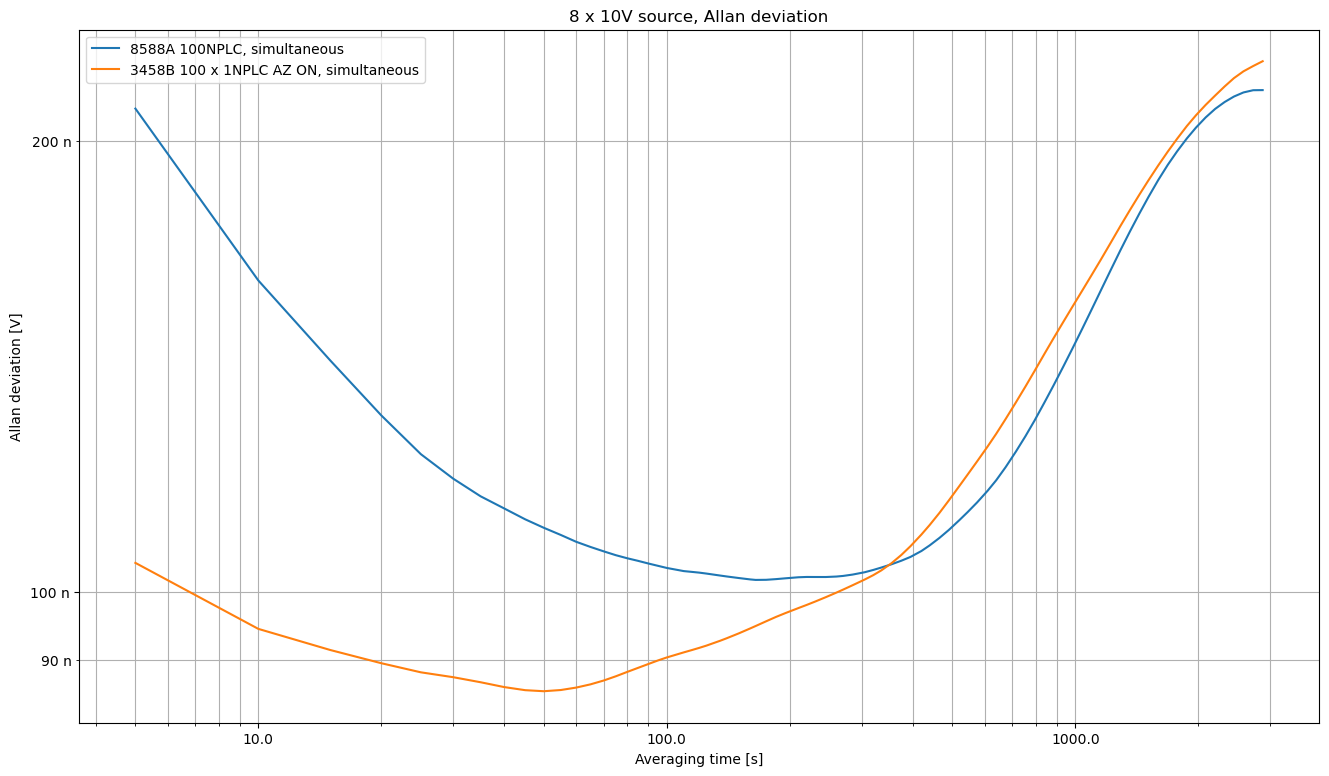

In [61]:
# Overlapping Allan deviation without detrending.
def allan(v, period):
    v = np.asarray(v)
    m_values = np.unique(np.logspace(0, np.log10(len(v)//10), 120).astype(int))
    sums = np.r_[0, np.cumsum(v-v.mean())]
    adev = []
    for m in m_values:
        avg = (sums[m:]-sums[:-m])/m
        adev.append(np.sqrt(np.mean((avg[m:]-avg[:-m])**2)/2))
    return m_values*period, np.array(adev)

def plot_allan(v, period, meter_name):
    t, a = allan(v, period)
    plt.plot(t, a, label=meter_name)
    i = np.argmin(a)
    print(f'{meter_name}: min {a[i]*1e9:.1f} nV at {t[i]:g} s')

fig, ax = plt.subplots(figsize=(16,9))
plt.loglog()
plt.title('8 x 10V source, Allan deviation')
plot_allan(f100, 5, '8588A 100NPLC, simultaneous')
plot_allan(k100, 5, '3458B 100 x 1NPLC AZ ON, simultaneous')
plt.xlabel('Averaging time [s]')
plt.ylabel('Allan deviation [V]')
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
plt.grid(True, which='both')
plt.legend()
plt.show()